# Comparative Analysis of Snowball and Lancaster Stemming Algorithms
---

### Project Objective

This project compares two stemming algorithms: **Snowball (Porter2)** and **Lancaster (Paice–Husk)**. Stemming reduces words to a common stem by applying rules that remove or modify word endings.

The objective is to evaluate how these algorithms affect **vocabulary size**, **processing time**, and **sentiment classification** of IMDb reviews. A no-stemming approach (Baseline) is also included for comparison.

In [1]:
# 1. Standard Libraries
import re
import html
import time
from collections import Counter

# 2. Data Manipulation
import numpy as np
import pandas as pd

# 3. Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# 4. Natural Language Processing (NLP)
from nltk.stem import SnowballStemmer, LancasterStemmer
from sklearn.feature_extraction.text import (
    ENGLISH_STOP_WORDS,
    TfidfVectorizer
)

# 5. Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# 6. Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 7. Display Settings
pd.set_option("display.max_colwidth", 150)
sns.set_theme(style="whitegrid")

---

## 1. Data Loading

The project uses the [**IMDb Dataset of 50K Movie Reviews**](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews).

It contains 50,000 English-language movie reviews divided into two categories:

- **Positive** – a positive opinion of the movie.
- **Negative** – a negative opinion of the movie.

The dataset has two main columns:

- **review** – the text of the movie review.
- **sentiment** – the review's sentiment label.

These data are used to investigate the impact of different stemming algorithms on text classification.

In [2]:
df = pd.read_csv("IMDB Dataset.csv")
df.head()

,review,sentiment
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened ...",positive
1,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometim...",positive
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted ...",positive
3,Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />Thi...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is a visually stunning film to watch. Mr. Mattei offers us a vivid portrait about human relations. Thi...",positive


---

## 2. Exploratory Data Analysis (EDA)

Before applying the stemming algorithms, it is necessary to examine the structure and quality of the data.

The analysis includes checking dataset dimensions, variable types, missing values, duplicate records, and class distribution.

In [3]:
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 50,000
Number of columns: 2


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB


In [5]:
missing_values = df.isnull().sum()

missing_values

review       0
sentiment    0
dtype: int64

In [6]:
duplicates = df.duplicated().sum()

print(f"Number of duplicate records: {duplicates:,}")
print(f"Percentage of duplicates: {duplicates / len(df) * 100:.2f}%")

Number of duplicate records: 418
Percentage of duplicates: 0.84%


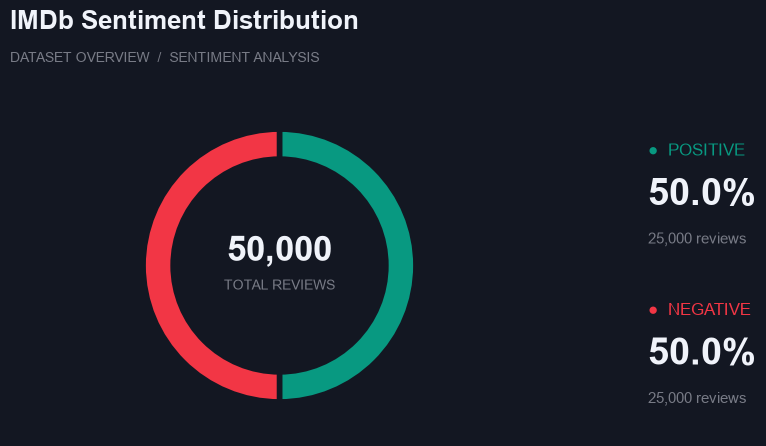

In [7]:
counts = df["sentiment"].value_counts()
positive = counts.get("positive", 0)
negative = counts.get("negative", 0)
total = positive + negative

bg = "#131722"
green = "#089981"
red = "#F23645"
white = "#F0F3FA"
gray = "#787B86"

fig = plt.figure(figsize=(11, 5.5), facecolor=bg)

fig.text(
    0.07, 0.88,
    "IMDb Sentiment Distribution",
    color=white, fontsize=19, fontweight="bold"
)

fig.text(
    0.07, 0.82,
    "DATASET OVERVIEW  /  SENTIMENT ANALYSIS",
    color=gray, fontsize=10
)

ax = fig.add_axes((0.08, 0.14, 0.47, 0.62))
ax.set_facecolor(bg)

ax.pie(
    [positive, negative],
    colors=[green, red],
    startangle=90,
    counterclock=False,
    wedgeprops={
        "width": 0.22,
        "edgecolor": bg,
        "linewidth": 4
    }
)

ax.text(
    0, 0.10, f"{total:,}",
    ha="center", va="center",
    fontsize=25, fontweight="bold", color=white
)

ax.text(
    0, -0.15, "TOTAL REVIEWS",
    ha="center", va="center",
    fontsize=10, color=gray
)

fig.text(0.65, 0.65, "●  POSITIVE", color=green, fontsize=12)
fig.text(
    0.65, 0.56,
    f"{positive / total * 100:.1f}%",
    color=white, fontsize=27, fontweight="bold"
)
fig.text(0.65, 0.49, f"{positive:,} reviews", color=gray, fontsize=11)

fig.text(0.65, 0.36, "●  NEGATIVE", color=red, fontsize=12)
fig.text(
    0.65, 0.27,
    f"{negative / total * 100:.1f}%",
    color=white, fontsize=27, fontweight="bold"
)
fig.text(0.65, 0.20, f"{negative:,} reviews", color=gray, fontsize=11)

plt.show()

In [8]:
class_counts = df["sentiment"].value_counts()

class_percentages = (
    df["sentiment"].value_counts(normalize=True) * 100
)

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

class_distribution

,Count,Percentage (%)
sentiment,,
positive,25000,50.0
negative,25000,50.0


In [9]:
df["word_count"] = df["review"].str.split().str.len()
df["word_count"].describe()

count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: word_count, dtype: float64

In [10]:
html_mask = df["review"].str.contains(
    r"<[^>]+>",
    regex=True,
    na=False
)

html_count = html_mask.sum()

print(f"Reviews containing HTML tags: {html_count:,}")
print(f"Percentage: {html_count / len(df) * 100:.2f}%")

Reviews containing HTML tags: 29,202
Percentage: 58.40%


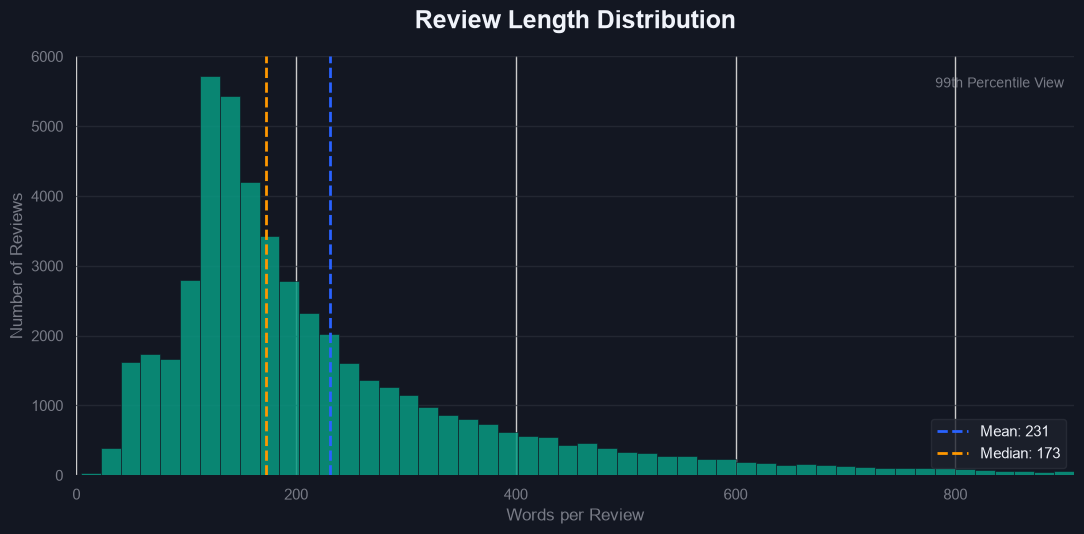

In [11]:
data = df["word_count"].dropna()

mean_val = data.mean()
median_val = data.median()
upper_limit = data.quantile(0.99)

bg = "#131722"
green = "#089981"
blue = "#2962FF"
orange = "#FF9800"
white = "#F0F3FA"
gray = "#787B86"

fig, ax = plt.subplots(figsize=(11, 5.5))
fig.patch.set_facecolor(bg)
ax.set_facecolor(bg)

filtered = data[data <= upper_limit]

ax.hist(
    filtered,
    bins=50,
    color=green,
    alpha=0.85,
    edgecolor=bg,
    linewidth=0.5
)

ax.axvline(
    mean_val, color=blue,
    linestyle="--", linewidth=2,
    label=f"Mean: {mean_val:.0f}"
)

ax.axvline(
    median_val, color=orange,
    linestyle="--", linewidth=2,
    label=f"Median: {median_val:.0f}"
)

ax.set_title(
    "Review Length Distribution",
    color=white, fontsize=18,
    fontweight="bold", pad=20
)

ax.set_xlabel("Words per Review", color=gray)
ax.set_ylabel("Number of Reviews", color=gray)

ax.set_xlim(0, upper_limit)
ax.tick_params(colors=gray)

ax.grid(axis="y", color="#2A2E39", alpha=0.7)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.legend(
    facecolor="#1E222D",
    edgecolor="#2A2E39",
    labelcolor=white
)

ax.text(
    0.99, 0.95,
    "99th Percentile View",
    transform=ax.transAxes,
    ha="right", va="top",
    color=gray, fontsize=10
)

plt.tight_layout()
plt.show()

### 2.1. Most Frequent Words Analysis

This section examines the frequency of words in the movie reviews.

Basic text processing is performed, including:

- Removing HTML tags.
- Converting text to lowercase.
- Splitting text into individual words (tokenization).
- Excluding common stop words from the visualization.

The 20 most frequent words in the dataset are displayed.

This analysis helps identify the main lexical characteristics of the reviews and the terms used most frequently.

In [12]:
def tokenize_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower()
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text)

all_words = Counter()
positive_words = Counter()
negative_words = Counter()

for review, sentiment in zip(df["review"], df["sentiment"]):
    tokens = tokenize_text(review)

    all_words.update(tokens)

    if sentiment == "positive":
        positive_words.update(tokens)
    elif sentiment == "negative":
        negative_words.update(tokens)

stop_words = set(ENGLISH_STOP_WORDS) - {
    "no", "not", "never", "nor"
}

def filter_words(counter):
    return Counter({
        word: count
        for word, count in counter.items()
        if word not in stop_words and len(word) >= 3
    })

filtered_words = filter_words(all_words)

top_20 = filtered_words.most_common(20)

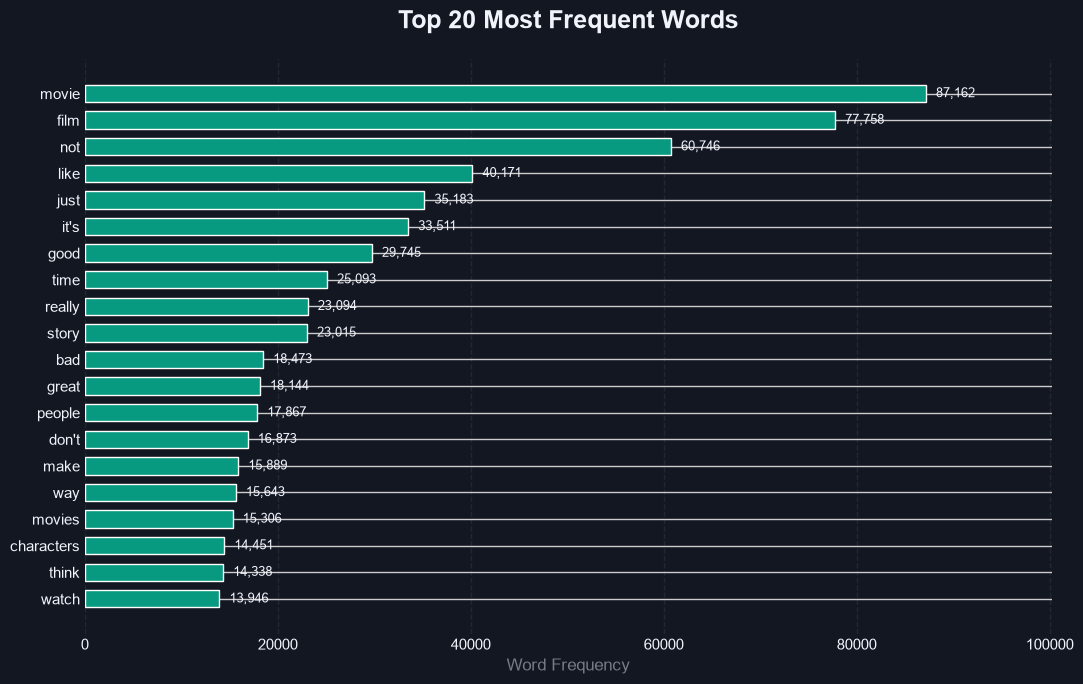

In [13]:
bg = "#131722"
green = "#089981"
white = "#F0F3FA"
gray = "#787B86"
grid = "#2A2E39"

words, frequencies = zip(*top_20)

fig, ax = plt.subplots(figsize=(11, 7))
fig.patch.set_facecolor(bg)
ax.set_facecolor(bg)

bars = ax.barh(
    words[::-1],
    frequencies[::-1],
    color=green,
    height=0.65
)

ax.set_title(
    "Top 20 Most Frequent Words",
    color=white, fontsize=18,
    fontweight="bold", pad=22
)

ax.set_xlabel("Word Frequency", color=gray)
ax.tick_params(colors=white, length=0)

ax.grid(axis="x", color=grid, linestyle="--", alpha=0.7)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xlim(0, max(frequencies) * 1.15)

for bar in bars:
    ax.text(
        bar.get_width() + max(frequencies) * 0.012,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width()):,}",
        va="center", color=white, fontsize=9
    )

plt.tight_layout()
plt.show()

### 2.2. Word Frequency by Sentiment

The most frequent words are examined separately in positive and negative reviews.

The goal is to identify differences in vocabulary usage between the two classes.

For each class, the 15 most frequent words are displayed after excluding stop words from the visualization.

The results allow the lexical characteristics of positive and negative opinions to be compared and help identify words that may be relevant to sentiment classification.

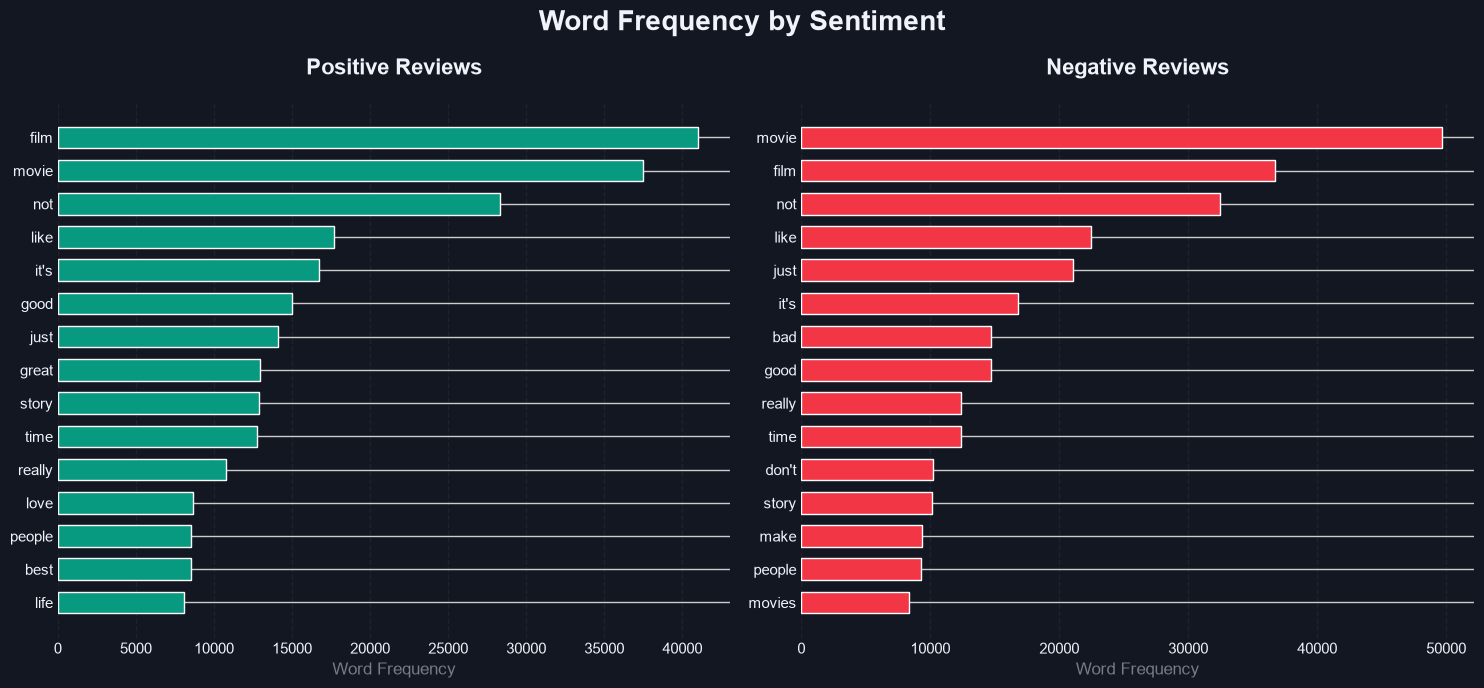

In [14]:
pos_filtered = filter_words(positive_words)
neg_filtered = filter_words(negative_words)

top_pos = pos_filtered.most_common(15)
top_neg = neg_filtered.most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
fig.patch.set_facecolor(bg)

datasets = [
    (top_pos, "Positive Reviews", "#089981"),
    (top_neg, "Negative Reviews", "#F23645")
]

for ax, (data, title, color) in zip(axes, datasets):

    words, counts = zip(*data)

    ax.set_facecolor(bg)

    ax.barh(
        words[::-1],
        counts[::-1],
        color=color,
        height=0.65
    )

    ax.set_title(
        title,
        color=white,
        fontsize=16,
        fontweight="bold",
        pad=20
    )

    ax.set_xlabel("Word Frequency", color=gray)
    ax.tick_params(colors=white, length=0)

    ax.grid(axis="x", color=grid, linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    "Word Frequency by Sentiment",
    color=white,
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### 2.3. Vocabulary Size Analysis

Vocabulary size is the number of unique words in the dataset.

The following are calculated:

- Total number of unique words.
- Number of unique words in positive reviews.
- Number of unique words in negative reviews.
- Number of words shared by both classes.
- Number of words unique to each class.

This analysis uses all tokenized words without removing stop words.

The resulting vocabulary size serves as a baseline for subsequent comparisons with Snowball and Lancaster.

Stemming is expected to reduce the number of unique word forms by merging different forms of the same words.

In [15]:
vocab_all = set(all_words.keys())
vocab_pos = set(positive_words.keys())
vocab_neg = set(negative_words.keys())

total_unique = len(vocab_all)
pos_unique = len(vocab_pos)
neg_unique = len(vocab_neg)

shared = len(vocab_pos & vocab_neg)
pos_only = len(vocab_pos - vocab_neg)
neg_only = len(vocab_neg - vocab_pos)

vocab_stats = pd.DataFrame({
    "Metric": [
        "Total Unique Words",
        "Positive Vocabulary",
        "Negative Vocabulary",
        "Shared Words",
        "Positive Only",
        "Negative Only"
    ],
    "Count": [
        total_unique,
        pos_unique,
        neg_unique,
        shared,
        pos_only,
        neg_only
    ]
})

vocab_stats

,Metric,Count
0,Total Unique Words,109526
1,Positive Vocabulary,81178
2,Negative Vocabulary,77266
3,Shared Words,48918
4,Positive Only,32260
5,Negative Only,28348


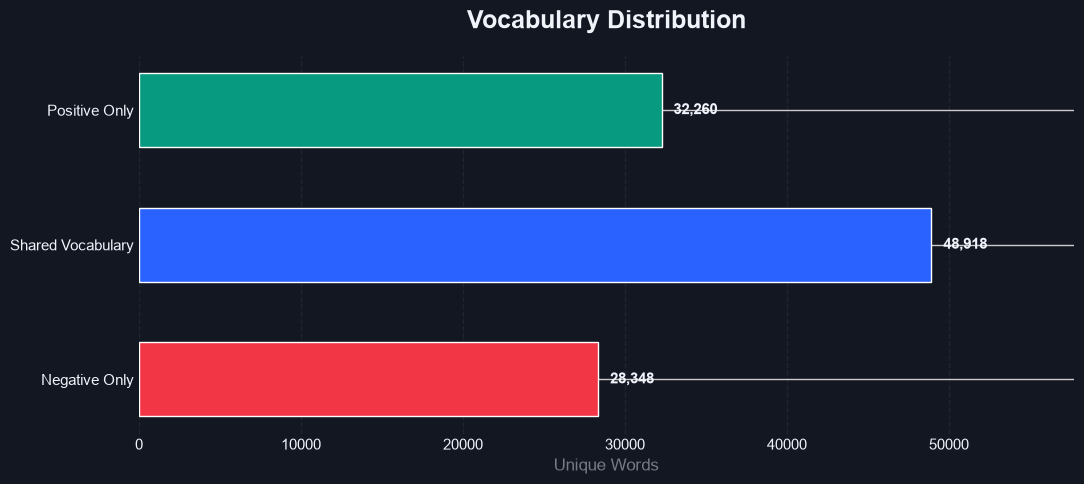

In [16]:
labels = [
    "Positive Only",
    "Shared Vocabulary",
    "Negative Only"
]

values = [pos_only, shared, neg_only]
colors = ["#089981", "#2962FF", "#F23645"]

fig, ax = plt.subplots(figsize=(11, 5))
fig.patch.set_facecolor(bg)
ax.set_facecolor(bg)

bars = ax.barh(
    labels,
    values,
    color=colors,
    height=0.55
)

ax.invert_yaxis()

ax.set_title(
    "Vocabulary Distribution",
    fontsize=18,
    color=white,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Unique Words", color=gray)
ax.tick_params(colors=white, length=0)

ax.grid(axis="x", color=grid, linestyle="--", alpha=0.6)
ax.set_axisbelow(True)

ax.set_xlim(0, max(values) * 1.18)

for bar in bars:
    ax.text(
        bar.get_width() + max(values) * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width()):,}",
        va="center",
        color=white,
        fontsize=11,
        fontweight="bold"
    )

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

---

## 3. Text Preprocessing

Text preprocessing is an important stage in Natural Language Processing (NLP). Its purpose is to convert raw text data into a standardized format.

The goal is to provide identical input data for an objective comparison of Snowball and Lancaster.

### 3.1. Duplicate Removal

Duplicate reviews can affect the reliability of the analysis and the evaluation of the models.

Removing them prevents identical texts from being used multiple times and reduces the risk that the same review appears in both the training and test sets.

In [17]:
df_prepared = df[["review", "sentiment"]].copy()

original_count = len(df_prepared)

df_prepared = df_prepared.drop_duplicates(
    subset=["review"]
).copy()

removed_duplicates = original_count - len(df_prepared)

print(f"Original records: {original_count:,}")
print(f"Removed duplicates: {removed_duplicates:,}")
print(f"Remaining records: {len(df_prepared):,}")

Original records: 50,000
Removed duplicates: 418
Remaining records: 49,582


### 3.2. Text Cleaning and Normalization

Text cleaning involves several consecutive operations:

- **HTML Decoding** – converting HTML entities into regular text characters.
- **HTML Removal** – removing HTML tags such as `<br />`.
- **Lowercasing** – converting uppercase letters to lowercase.
- **Special Character Removal** – removing digits, punctuation, and other unnecessary characters.
- **Tokenization** – splitting text into individual words.

The `tokenize_text()` function defined during EDA is reused to keep the text-processing method consistent.

Apostrophes in English contractions are preserved during initial cleaning. Stop words are not removed because some, such as "not" and "never", carry important information for sentiment analysis. The vectorization stage later uses its own tokenizer.

In [18]:
df_prepared["clean_review"] = df_prepared["review"].apply(
    lambda text: " ".join(tokenize_text(text))
)

comparison = df_prepared[
    ["review", "clean_review"]
].head(5)

comparison

,review,clean_review
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened ...",one of the other reviewers has mentioned that after watching just oz episode you'll be hooked they are right as this is exactly what happened with...
1,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometim...",a wonderful little production the filming technique is very unassuming very old time bbc fashion and gives a comforting and sometimes discomfortin...
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted ...",i thought this was a wonderful way to spend time on a too hot summer weekend sitting in the air conditioned theater and watching a light hearted c...
3,Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />Thi...,basically there's a family where a little boy jake thinks there's a zombie in his closet his parents are fighting all the time this movie is slowe...
4,"Petter Mattei's ""Love in the Time of Money"" is a visually stunning film to watch. Mr. Mattei offers us a vivid portrait about human relations. Thi...",petter mattei's love in the time of money is a visually stunning film to watch mr mattei offers us a vivid portrait about human relations this is ...


### 3.3. Validation of Cleaned Data

After normalization, the data are checked again for empty texts and duplicate reviews.

Two originally different texts may become identical after removing HTML tags, punctuation, and other characters.

Empty texts and newly identified duplicates are removed before splitting the data.

This reduces the risk of data leakage between the training and test sets.

In [19]:
empty_reviews = df_prepared["clean_review"].eq("").sum()

normalized_duplicates = df_prepared[
    "clean_review"
].duplicated().sum()

df_prepared = df_prepared[
    df_prepared["clean_review"] != ""
].copy()

df_prepared = df_prepared.drop_duplicates(
    subset=["clean_review"]
).reset_index(drop=True)

print(f"Empty reviews: {empty_reviews:,}")
print(f"Normalized duplicates: {normalized_duplicates:,}")
print(f"Final dataset size: {len(df_prepared):,}")

Empty reviews: 0
Normalized duplicates: 6
Final dataset size: 49,576


### 3.4. Train/Test Split

For model training and evaluation, the dataset is divided into two parts:

- **Training Set (80%)** – used to train the models.
- **Test Set (20%)** – used to evaluate model performance on unseen data.

A stratified split is used to approximately preserve the proportion of positive and negative reviews.

The `random_state=42` parameter makes the experiment reproducible.

The same split is used for all approaches, ensuring that the results are comparable.

In [20]:
train_df, test_df = train_test_split(
    df_prepared,
    test_size=0.20,
    random_state=42,
    stratify=df_prepared["sentiment"]
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

X_train = train_df["clean_review"]
X_test = test_df["clean_review"]

label_map = {"negative": 0, "positive": 1}

y_train = train_df["sentiment"].map(label_map)
y_test = test_df["sentiment"].map(label_map)

print(f"Training samples: {len(X_train):,}")
print(f"Testing samples: {len(X_test):,}")
print(f"Total samples: {len(X_train) + len(X_test):,}")

Training samples: 39,660
Testing samples: 9,916
Total samples: 49,576


### 3.5. Training and Test Set Validation

After splitting, the sizes of the two datasets, class distributions, and any overlap between texts are checked.

The main goal is to confirm that:

- The training/test ratio is approximately 80/20.
- Both classes retain an approximately balanced distribution.
- No identical cleaned reviews appear in both datasets.

This validation is necessary for a reliable comparison of the algorithms and subsequent evaluation of the ML models.

In [21]:
distribution = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Testing": y_test.value_counts()
})

# 0 = Negative, 1 = Positive; preserve this order explicitly
distribution = distribution.reindex([0, 1])
distribution.index = ["Negative", "Positive"]

display(distribution)

overlap = len(set(X_train) & set(X_test))

print(f"Overlapping reviews: {overlap}")

assert overlap == 0, "Data leakage detected!"
assert not X_train.isna().any()
assert not X_test.isna().any()
assert not y_train.isna().any()
assert not y_test.isna().any()

print("Data validation passed.")

,Training,Testing
Negative,19756,4939
Positive,19904,4977


Overlapping reviews: 0
Data validation passed.


---

## 4. Comparative Analysis of Snowball and Lancaster

Stemming is a Natural Language Processing technique that reduces words to a common stem by removing or modifying their endings.

This section investigates two algorithms:

- **Snowball (Porter2)** – applies successive word-transformation rules and generally performs less aggressive stemming.
- **Lancaster (Paice–Husk)** – uses an iterative approach and more aggressive word reduction.

### 4.1. Importing and Initializing the Algorithms

The two algorithms are implemented using NLTK (Natural Language Toolkit).

- **SnowballStemmer** – implements Snowball stemming for English.
- **LancasterStemmer** – implements the Lancaster algorithm.

Both algorithms use predefined rules and do not require training on the dataset.

In [22]:
snowball = SnowballStemmer("english")
lancaster = LancasterStemmer()

print("Snowball initialized successfully.")
print("Lancaster initialized successfully.")

Snowball initialized successfully.
Lancaster initialized successfully.


### 4.2. Stemming Demonstration with Sample Words

Before processing the full dataset, an experiment is conducted using a selection of English words.

The aim is to demonstrate the differences between Snowball and Lancaster when transforming various grammatical forms.

The results help determine:

- How much each algorithm shortens words.
- Whether different forms of the same word are reduced to a common stem.
- Which words produce different results across the algorithms.
- Whether aggressive stemming removes substantial parts of words.

In [23]:
words = [
    "running",
    "runner",
    "runs",
    "studies",
    "studying",
    "happiness",
    "happily",
    "connection",
    "connections",
    "relational",
    "organization",
    "beautifully",
    "terrible",
    "terribly",
    "movies",
    "acting",
    "interesting",
    "better",
    "worst",
    "amazing"
]

stem_comparison = pd.DataFrame({
    "Original": words,
    "Snowball": [snowball.stem(w) for w in words],
    "Lancaster": [lancaster.stem(w) for w in words]
})

stem_comparison

,Original,Snowball,Lancaster
0,running,run,run
1,runner,runner,run
2,runs,run,run
3,studies,studi,study
4,studying,studi,study
5,happiness,happi,happy
6,happily,happili,happy
7,connection,connect,connect
8,connections,connect,connect
9,relational,relat,rel


### 4.3. Applying the Algorithms to the Text Data

Following the demonstration, both stemming algorithms are applied to all previously cleaned reviews.

A stemming lookup table (stemming mapping) is used to optimize processing.

Each unique word is stemmed only once, and its resulting stem is reused every time the word occurs in the texts.

This reduces redundant computations.

Separate training and test texts are produced for each algorithm, while the original cleaned data remain unchanged.

The time needed to build the mappings and transform the texts is measured.

In [24]:
all_texts = pd.concat(
    [X_train, X_test],
    ignore_index=True
)

vocabulary = set()

for text in all_texts:
    vocabulary.update(text.split())

print(f"Original vocabulary size: {len(vocabulary):,}")

def apply_stemming(stemmer, vocabulary, X_train, X_test):

    start = time.perf_counter()

    stem_map = {
        word: stemmer.stem(word)
        for word in vocabulary
    }

    train_stemmed = X_train.apply(
        lambda text: " ".join(
            stem_map[word] for word in text.split()
        )
    )

    test_stemmed = X_test.apply(
        lambda text: " ".join(
            stem_map[word] for word in text.split()
        )
    )

    elapsed = time.perf_counter() - start

    return train_stemmed, test_stemmed, stem_map, elapsed

(
    X_train_snowball,
    X_test_snowball,
    snowball_map,
    snowball_time
) = apply_stemming(
    snowball, vocabulary, X_train, X_test
)

(
    X_train_lancaster,
    X_test_lancaster,
    lancaster_map,
    lancaster_time
) = apply_stemming(
    lancaster, vocabulary, X_train, X_test
)

print("Stemming completed successfully.")
print(f"Snowball processing time: {snowball_time:.3f} s")
print(f"Lancaster processing time: {lancaster_time:.3f} s")

Original vocabulary size: 109,526
Stemming completed successfully.
Snowball processing time: 6.166 s
Lancaster processing time: 6.520 s


### 4.4. Comparing Transformed Reviews

The outputs of the two algorithms are visually inspected.

For selected reviews, three text representations are compared:

- Original cleaned text (Baseline).
- Text after Snowball stemming.
- Text after Lancaster stemming.

This comparison illustrates differences in word reduction and the preservation of textual information.

In [25]:
review_comparison = pd.DataFrame({
    "Original (Cleaned)": X_test.iloc[:5].str[:200].values,
    "Snowball": X_test_snowball.iloc[:5].str[:200].values,
    "Lancaster": X_test_lancaster.iloc[:5].str[:200].values
})

display(review_comparison)

assert len(X_train_snowball) == len(X_train)
assert len(X_test_snowball) == len(X_test)
assert len(X_train_lancaster) == len(X_train)
assert len(X_test_lancaster) == len(X_test)

print("Dataset validation passed.")

,Original (Cleaned),Snowball,Lancaster
0,this columbo episode is probably noted more for the director steven spielberg as one of his early films it should be looked at for jack cassidy's ...,this columbo episod is probabl note more for the director steven spielberg as one of his earli film it should be look at for jack cassidi role as ...,thi columbo episod is prob not mor for the direct stev spielberg as on of his ear film it should be look at for jack cassidy's rol as the murd who...
1,i was born in with not much parental guidance as far as what i watched on tv as a kid in the s i always loved this movie and the french connection...,i was born in with not much parent guidanc as far as what i watch on tv as a kid in the s i alway love this movi and the french connect and would ...,i was born in with not much par guid as far as what i watch on tv as a kid in the s i alway lov thi movy and the french connect and would alway tr...
2,the movie is bad nothing special just a kid movie with no serious thing in it there is though one reason to watch this for the animal talk some of...,the movi is bad noth special just a kid movi with no serious thing in it there is though one reason to watch this for the anim talk some of them a...,the movy is bad noth spec just a kid movy with no sery thing in it ther is though on reason to watch thi for the anim talk som of them ar so funny...
3,enhanced by the expressive cinematography of agnes godard beau travail golden door is a visually striking tone poem that follows the journey of a ...,enhanc by the express cinematographi of agn godard beau travail golden door is a visual strike tone poem that follow the journey of a peasant fami...,enh by the express cinematograph of agn godard beau travail gold door is a vis striking ton poem that follow the journey of a peas famy from their...
4,normally i don't bother wasting my time writing comments for junk like this that i forget almost as soon as i see it but since i saw this movie ju...,normal i don't bother wast my time write comment for junk like this that i forget almost as soon as i see it but sinc i saw this movi just yesterd...,norm i don't both wast my tim writ com for junk lik thi that i forget almost as soon as i see it but sint i saw thi movy just yesterday on on of t...


Dataset validation passed.


### 4.5. Vocabulary Size Comparison (Vocabulary Reduction)

One of the main effects of stemming algorithms is a reduction in the number of unique word forms.

Two metrics are used:

- **Vocabulary Size** – the number of unique words after processing.
- **Vocabulary Reduction (%)** – the percentage decrease in vocabulary size relative to the original cleaned text.

Three approaches are compared:

1. Baseline – no stemming.
2. Snowball – after applying Porter2.
3. Lancaster – after applying Paice–Husk.

A smaller vocabulary can reduce the dimensionality of text representations, but excessive reduction may merge words with different meanings.

Therefore, greater vocabulary reduction does not necessarily imply higher classification accuracy.

In [26]:
baseline_size = len(vocabulary)
snowball_size = len(set(snowball_map.values()))
lancaster_size = len(set(lancaster_map.values()))

snowball_reduction = (
    1 - snowball_size / baseline_size
) * 100

lancaster_reduction = (
    1 - lancaster_size / baseline_size
) * 100

results = pd.DataFrame({
    "Algorithm": [
        "Baseline",
        "Snowball",
        "Lancaster"
    ],
    "Vocabulary Size": [
        baseline_size,
        snowball_size,
        lancaster_size
    ],
    "Reduction (%)": [
        0,
        snowball_reduction,
        lancaster_reduction
    ],
    "Processing Time (s)": [
        np.nan,
        snowball_time,
        lancaster_time
    ]
})

display(
    results.style.format({
        "Vocabulary Size": "{:,.0f}",
        "Reduction (%)": "{:.2f}%",
        "Processing Time (s)": "{:.3f}"
    }, na_rep="—")
)

,Algorithm,Vocabulary Size,Reduction (%),Processing Time (s)
0,Baseline,"109,526",0.00%,—
1,Snowball,"68,932",37.06%,6.166
2,Lancaster,"66,784",39.02%,6.520


### 4.6. Visual Comparison of the Algorithms

The results are presented in two charts:

- **Vocabulary Size Comparison** – compares the number of unique word forms.
- **Processing Time Comparison** – compares the time needed for stemming and text transformation.

These visualizations make it easier to assess the differences between the algorithms in terms of word reduction and computational efficiency.

The same processing methodology is used for both algorithms.

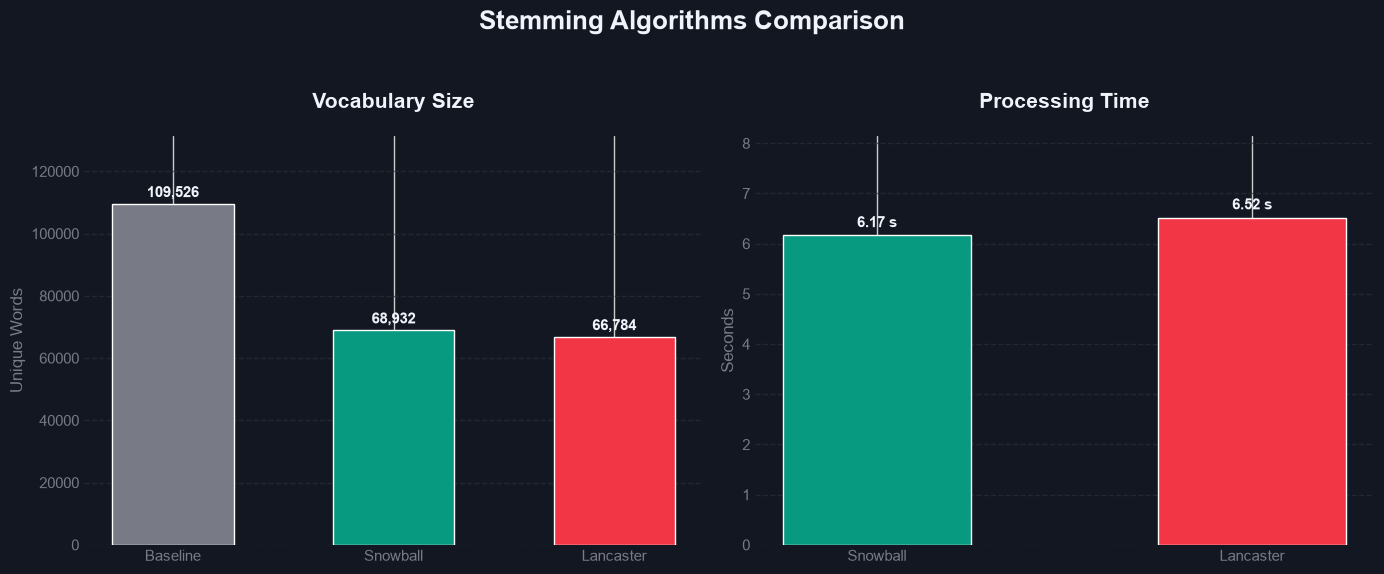

In [27]:
bg = "#131722"
white = "#F0F3FA"
gray = "#787B86"
grid = "#2A2E39"

colors = ["#787B86", "#089981", "#F23645"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.patch.set_facecolor(bg)

for ax in axes:
    ax.set_facecolor(bg)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color=grid, linestyle="--", alpha=0.7)
    ax.tick_params(colors=gray, length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)

bars1 = axes[0].bar(
    results["Algorithm"],
    results["Vocabulary Size"],
    color=colors,
    width=0.55
)

axes[0].set_title(
    "Vocabulary Size",
    color=white,
    fontsize=15,
    fontweight="bold",
    pad=20
)

axes[0].set_ylabel("Unique Words", color=gray)
axes[0].set_ylim(0, baseline_size * 1.2)

for bar, value in zip(bars1, results["Vocabulary Size"]):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + baseline_size * 0.02,
        f"{value:,}",
        ha="center",
        color=white,
        fontsize=11,
        fontweight="bold"
    )

time_values = [snowball_time, lancaster_time]

bars2 = axes[1].bar(
    ["Snowball", "Lancaster"],
    time_values,
    color=["#089981", "#F23645"],
    width=0.5
)

axes[1].set_title(
    "Processing Time",
    color=white,
    fontsize=15,
    fontweight="bold",
    pad=20
)

axes[1].set_ylabel("Seconds", color=gray)
axes[1].set_ylim(0, max(time_values) * 1.25)

for bar, value in zip(bars2, time_values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(time_values) * 0.025,
        f"{value:.2f} s",
        ha="center",
        color=white,
        fontsize=11,
        fontweight="bold"
    )

fig.suptitle(
    "Stemming Algorithms Comparison",
    color=white,
    fontsize=19,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

---

## 5. Machine Learning and Sentiment Classification

This section investigates the impact of Snowball and Lancaster on text classification performance.

Two techniques are used:

- **TF-IDF (Term Frequency–Inverse Document Frequency)** – converts text into numerical features.
- **Logistic Regression** – a binary classification algorithm.

Three models are trained under identical conditions:

1. **Baseline** – a model without stemming.
2. **Snowball** – a model using text processed with Snowball.
3. **Lancaster** – a model using text processed with Lancaster.

### Objectives

- Evaluate the impact of stemming on classification.
- Compare Accuracy, Precision, Recall, and F1-score.
- Measure model training time.
- Analyze classification errors.
- Identify the best-performing approach.

All models use identical training and test observations and the same hyperparameters.

### 5.1. Text Vectorization Using TF-IDF

Machine learning algorithms cannot directly process raw text data. Therefore, texts must be converted into numerical vectors.

TF-IDF is used for this purpose.

It estimates the importance of a word based on:

- **TF (Term Frequency)** – how often the word appears in a particular document.
- **IDF (Inverse Document Frequency)** – reduces the weight of words that occur across many documents.

Unigrams and bigrams (sequences of one or two words) are used.

TF-IDF is fitted only on the Training Set and then applied to the Test Set to prevent data leakage.

### 5.2. Training the Classification Models

Logistic Regression, a linear algorithm well suited to high-dimensional text features, is used for classification.

A separate Pipeline is created for each approach, containing:

1. TF-IDF vectorization.
2. A Logistic Regression classifier.

Hyperparameters are identical across all models to ensure a fair comparison.

Evaluation is performed on the previously held-out Test Set, which is not used for training.

In [28]:
datasets = {
    "Baseline": (X_train, X_test),
    "Snowball": (X_train_snowball, X_test_snowball),
    "Lancaster": (X_train_lancaster, X_test_lancaster)
}

models = {}
predictions = {}
metrics = []

for name, (train_text, test_text) in datasets.items():

    print(f"Training {name} model...")

    pipeline = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                max_features=50000,
                ngram_range=(1, 2),
                min_df=2,
                sublinear_tf=True
            )
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                solver="liblinear",
                random_state=42
            )
        )
    ])

    start = time.perf_counter()

    pipeline.fit(train_text, y_train)

    training_time = time.perf_counter() - start

    y_pred = pipeline.predict(test_text)

    models[name] = pipeline
    predictions[name] = y_pred

    metrics.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro"
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro"
        ),
        "F1-score": f1_score(
            y_test, y_pred, average="macro"
        ),
        "Training Time (s)": training_time
    })

    print(f"{name} completed in {training_time:.2f} s\n")

ml_results = pd.DataFrame(metrics)

display(ml_results.round(4))

Training Baseline model...
Baseline completed in 38.87 s

Training Snowball model...
Snowball completed in 35.39 s

Training Lancaster model...
Lancaster completed in 33.49 s



,Algorithm,Accuracy,Precision,Recall,F1-score,Training Time (s)
0,Baseline,0.9085,0.9089,0.9085,0.9085,38.8682
1,Snowball,0.9090,0.9093,0.9090,0.9090,35.3941
2,Lancaster,0.9064,0.9066,0.9064,0.9064,33.4888


### 5.3. Evaluating the Classification Models

Four main metrics are used to compare the models:

- **Accuracy** – the proportion of reviews classified correctly.
- **Precision** – how often predictions of a given class are correct.
- **Recall** – the proportion of actual examples of a class correctly identified.
- **F1-score** – the harmonic mean of Precision and Recall.

Precision, Recall, and F1-score are calculated using Macro Average, which gives both classes equal weight.

Model training time is also compared.

This makes it possible to assess both classification performance and computational efficiency.

### 5.4. Visual Comparison of Results

A comparative chart of the four main classification metrics is created to present the results more clearly.

The visualization shows whether Snowball or Lancaster improves performance compared with the model without stemming.

Special attention is paid to F1-score, which combines Precision and Recall into a balanced measure of classification performance.

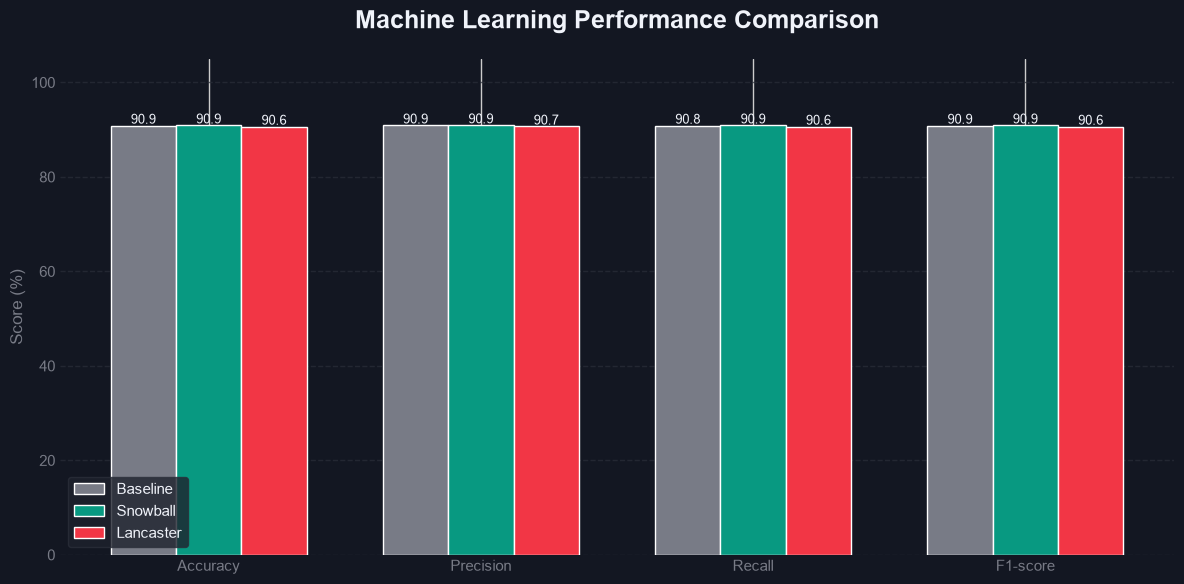

In [29]:
bg = "#131722"
white = "#F0F3FA"
gray = "#787B86"
grid = "#2A2E39"

colors = ["#787B86", "#089981", "#F23645"]

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

fig, ax = plt.subplots(figsize=(12, 6))

fig.patch.set_facecolor(bg)
ax.set_facecolor(bg)

x = np.arange(len(metric_names))
width = 0.24

for i, (_, row) in enumerate(ml_results.iterrows()):

    values = [row[metric] * 100 for metric in metric_names]

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=row["Algorithm"],
        color=colors[i]
    )

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.4,
            f"{value:.1f}",
            ha="center",
            color=white,
            fontsize=9
        )

ax.set_title(
    "Machine Learning Performance Comparison",
    color=white,
    fontsize=18,
    fontweight="bold",
    pad=22
)

ax.set_xticks(x)
ax.set_xticklabels(metric_names, color=white)

ax.set_ylabel("Score (%)", color=gray)
ax.set_ylim(0, 105)

ax.tick_params(colors=gray, length=0)

ax.grid(
    axis="y",
    color=grid,
    linestyle="--",
    alpha=0.7
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.legend(
    facecolor="#1E222D",
    edgecolor=grid,
    labelcolor=white
)

plt.tight_layout()
plt.show()

### 5.5. Error Analysis Using a Confusion Matrix

A Confusion Matrix shows the number of correct and incorrect predictions for each class.

Binary classification outcomes are divided into:

- **True Negative (TN)** – negative reviews correctly identified as negative.
- **True Positive (TP)** – positive reviews correctly identified as positive.
- **False Positive (FP)** – negative reviews incorrectly classified as positive.
- **False Negative (FN)** – positive reviews incorrectly classified as negative.

Comparing the Confusion Matrices of the three models helps analyze the mistakes made and differences in classification.

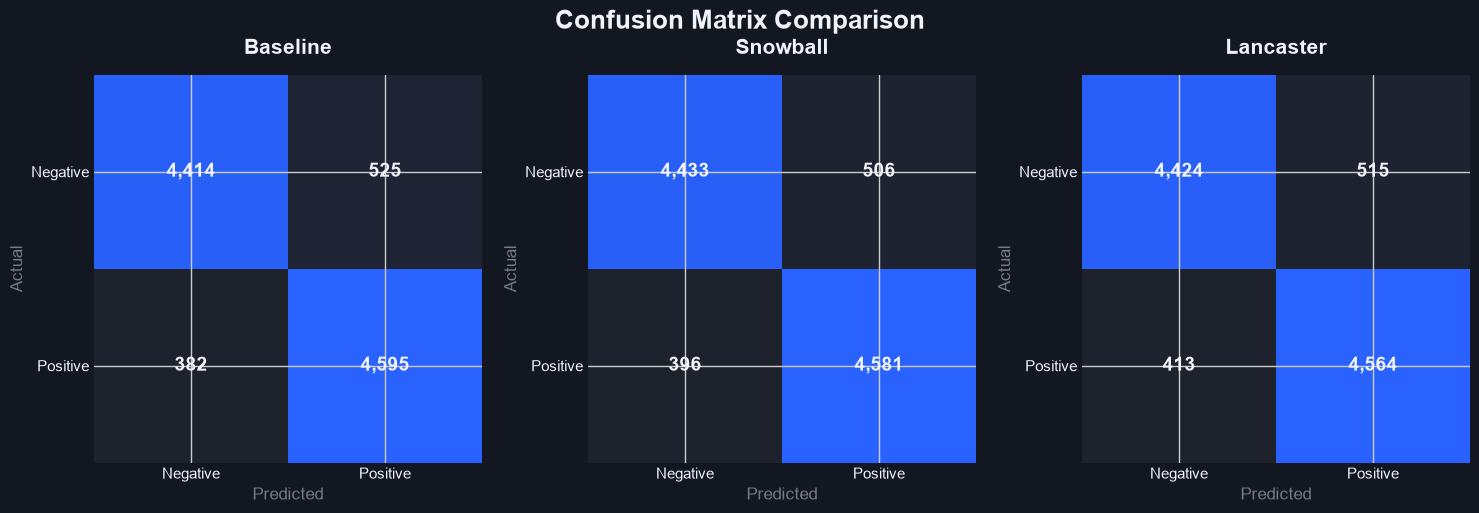

In [30]:
cmap = LinearSegmentedColormap.from_list(
    "trading_blue",
    ["#1E222D", "#2962FF"]
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

fig.patch.set_facecolor(bg)

for ax, (name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    ax.set_facecolor(bg)

    ax.imshow(cm, cmap=cmap)

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i,
                f"{cm[i, j]:,}",
                ha="center",
                va="center",
                color=white,
                fontsize=14,
                fontweight="bold"
            )

    ax.set_title(
        name,
        color=white,
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(["Negative", "Positive"])
    ax.set_yticklabels(["Negative", "Positive"])

    ax.tick_params(colors=white, length=0)

    ax.set_xlabel("Predicted", color=gray)
    ax.set_ylabel("Actual", color=gray)

    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    "Confusion Matrix Comparison",
    color=white,
    fontsize=19,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### 5.6. Conclusions from the Machine Learning Analysis

The three models use identical Train/Test observations, TF-IDF settings, and a Logistic Regression classifier.

- **Snowball** achieves the highest F1-score (**90.90%**), **0.05 percentage points** above Baseline (**90.85%**).
- **Lancaster** achieves an F1-score of **90.64%** – **0.26 percentage points** below Snowball.
- Measured TF-IDF and training times are **38.87 s** for Baseline, **35.39 s** for Snowball, and **33.49 s** for Lancaster.

**Conclusion:** Snowball provides a marginal improvement in F1-score, while Lancaster has the shortest TF-IDF and training time. These times **exclude stemming**; combined efficiency is examined in Section 6. The differences in classification performance are small and have not been tested for statistical significance.

---

## 6. Final Comparative Analysis and Conclusions

This final section summarizes the results of the comparison between Snowball (Porter2) and Lancaster (Paice–Husk).

Three approaches are considered:

1. **Baseline** – no stemming.
2. **Snowball** – moderate stemming using Porter2.
3. **Lancaster** – aggressive stemming using Paice–Husk.

### Main Comparison Criteria

- **Vocabulary Size** – the number of unique words after processing.
- **Vocabulary Reduction** – percentage reduction in vocabulary size.
- **Processing Time** – time required to perform stemming.
- **Training Time** – time required for TF-IDF vectorization and classifier training.
- **Accuracy and F1-score** – classification performance.

The objective is to determine which approach offers the best balance between vocabulary reduction, computational efficiency, and classification performance.

### 6.1. Summary of Experimental Results

Results from the vocabulary analysis and machine learning experiments are combined into a single comparison table.

Two additional metrics are calculated:

- **F1 Difference** – the difference in F1-score relative to Baseline, measured in percentage points.
- **Combined Time** – the sum of measured stemming time and TF-IDF vectorization and training time.

Combined Time excludes the initial text cleaning and prediction generation.

This gives a more complete comparison of computational costs across the approaches.

In [31]:
final_results = results.merge(
    ml_results,
    on="Algorithm",
    how="inner"
)

final_results["Stemming Time (s)"] = (
    final_results["Processing Time (s)"].fillna(0)
)

final_results["Combined Time (s)"] = (
    final_results["Stemming Time (s)"]
    + final_results["Training Time (s)"]
)

baseline_f1 = final_results.loc[
    final_results["Algorithm"] == "Baseline",
    "F1-score"
].iloc[0]

final_results["F1 Difference (pp)"] = (
    final_results["F1-score"] - baseline_f1
) * 100

final_table = final_results[[
    "Algorithm",
    "Vocabulary Size",
    "Reduction (%)",
    "Accuracy",
    "F1-score",
    "Stemming Time (s)",
    "Training Time (s)",
    "Combined Time (s)",
    "F1 Difference (pp)"
]]

display(
    final_table.style.format({
        "Vocabulary Size": "{:,.0f}",
        "Reduction (%)": "{:.2f}%",
        "Accuracy": "{:.2%}",
        "F1-score": "{:.2%}",
        "Stemming Time (s)": "{:.2f}",
        "Training Time (s)": "{:.2f}",
        "Combined Time (s)": "{:.2f}",
        "F1 Difference (pp)": "{:+.2f}"
    })
)

,Algorithm,Vocabulary Size,Reduction (%),Accuracy,F1-score,Stemming Time (s),Training Time (s),Combined Time (s),F1 Difference (pp)
0,Baseline,"109,526",0.00%,90.85%,90.85%,0.00,38.87,38.87,+0.00
1,Snowball,"68,932",37.06%,90.90%,90.90%,6.17,35.39,41.56,+0.05
2,Lancaster,"66,784",39.02%,90.64%,90.64%,6.52,33.49,40.01,-0.21


### 6.2. Classification Quality and Processing Time Comparison

Two charts are used to visualize the main results.

**F1-score Difference** shows the change in F1-score relative to Baseline. Positive values indicate improvement; negative values indicate worse classification performance.

**Combined Processing Time** shows the stemming time and model training time as separate components.

This helps distinguish the impact of stemming on model performance from its overall computational cost.

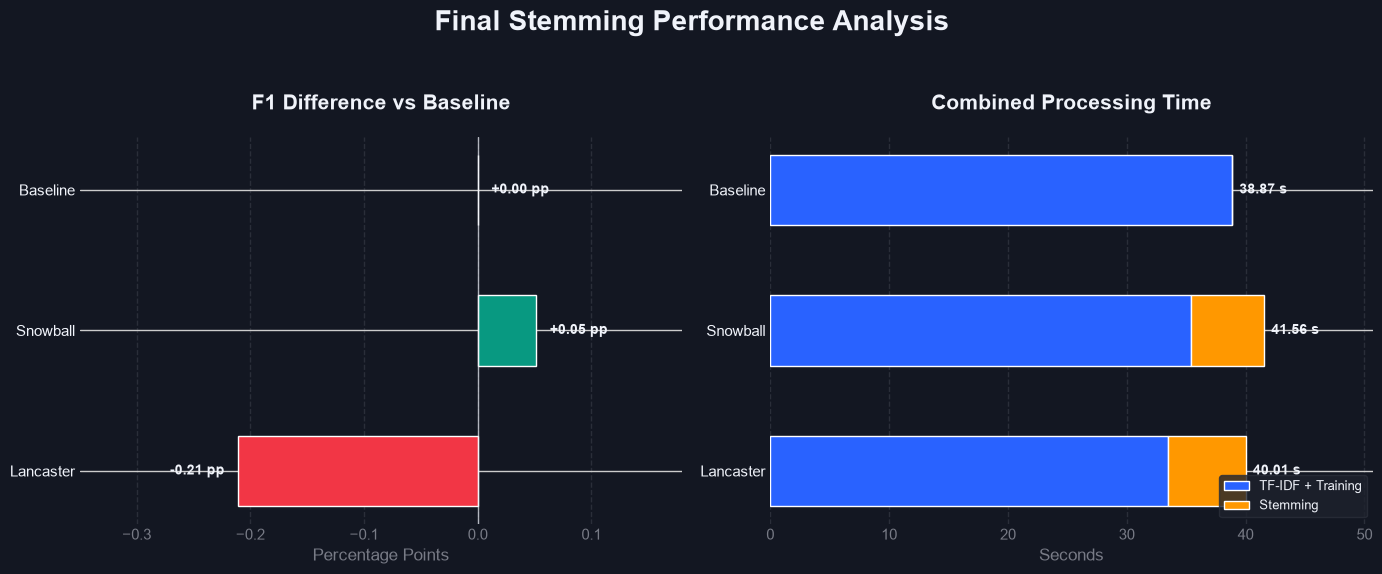

In [32]:
bg = "#131722"
panel = "#1E222D"
white = "#F0F3FA"
gray = "#787B86"
grid = "#2A2E39"

green = "#089981"
red = "#F23645"
blue = "#2962FF"
orange = "#FF9800"

names = final_results["Algorithm"].tolist()
f1_diff = final_results["F1 Difference (pp)"].values
training = final_results["Training Time (s)"].values
stemming = final_results["Stemming Time (s)"].values
combined = final_results["Combined Time (s)"].values

y = np.arange(len(names))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.patch.set_facecolor(bg)

for ax in axes:
    ax.set_facecolor(bg)
    ax.tick_params(colors=gray, length=0)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

ax1 = axes[0]

bar_colors = [
    gray if value == 0 else green if value > 0 else red
    for value in f1_diff
]

ax1.barh(
    y,
    f1_diff,
    color=bar_colors,
    height=0.5
)

ax1.axvline(0, color=white, linewidth=1, alpha=0.7)

ax1.set_yticks(y)
ax1.set_yticklabels(names, color=white)
ax1.invert_yaxis()

ax1.set_xlim(-0.35, 0.18)
ax1.set_xlabel("Percentage Points", color=gray)

ax1.set_title(
    "F1 Difference vs Baseline",
    color=white,
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax1.grid(axis="x", color=grid, linestyle="--")

for i, value in enumerate(f1_diff):
    offset = 0.012 if value >= 0 else -0.012

    ax1.text(
        value + offset,
        i,
        f"{value:+.2f} pp",
        color=white,
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=10,
        fontweight="bold"
    )

ax2 = axes[1]

ax2.barh(
    y,
    training,
    color=blue,
    height=0.5,
    label="TF-IDF + Training"
)

ax2.barh(
    y,
    stemming,
    left=training,
    color=orange,
    height=0.5,
    label="Stemming"
)

ax2.set_yticks(y)
ax2.set_yticklabels(names, color=white)
ax2.invert_yaxis()

ax2.set_xlim(0, max(combined) * 1.22)
ax2.set_xlabel("Seconds", color=gray)

ax2.set_title(
    "Combined Processing Time",
    color=white,
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax2.grid(axis="x", color=grid, linestyle="--")

for i, value in enumerate(combined):
    ax2.text(
        value + 0.6,
        i,
        f"{value:.2f} s",
        color=white,
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax2.legend(
    loc="lower right",
    facecolor=panel,
    edgecolor=grid,
    labelcolor=white,
    fontsize=9
)

fig.suptitle(
    "Final Stemming Performance Analysis",
    color=white,
    fontsize=20,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

### 6.3. Interpretation of Results

#### 6.3.1. Vocabulary Reduction

The initial vocabulary contains **109,526** unique words. Snowball reduces it to **68,932** (**37.06%**), while Lancaster reduces it to **66,784** (**39.02%**). Lancaster applies more aggressive vocabulary reduction, but a smaller vocabulary does not guarantee more accurate classification.

#### 6.3.2. Classification Performance

Snowball achieves the highest F1-score (**90.90%**), followed by Baseline (**90.85%**) and Lancaster (**90.64%**). Snowball's advantage over Baseline is only **0.05 percentage points**.

#### 6.3.3. Computational Efficiency

The measured stemming time is **6.17 s** for Snowball and **6.52 s** for Lancaster. TF-IDF vectorization and training take **35.39 s** and **33.49 s**, respectively, compared with **38.87 s** for Baseline.

The sum of the measured stages is:

| Approach | Stemming | TF-IDF + Training | Combined Time |
|---|---:|---:|---:|
| Baseline | — | 38.87 s | **38.87 s** |
| Snowball | 6.17 s | 35.39 s | 41.56 s |
| Lancaster | 6.52 s | 33.49 s | 40.01 s |

**Baseline has the shortest total measured time.** The values come from a single run; they exclude the shared text-cleaning stage and prediction time.

#### 6.3.4. Key Takeaway

**Snowball delivers the highest F1-score; Lancaster reduces the vocabulary the most; Baseline is the fastest based on the sum of measured stages.** The choice of approach depends on the priority given to quality, dimensionality, and computational cost.

### 6.4. Limitations of the Study

- **Single dataset:** The results apply to English-language IMDb movie reviews and cannot automatically be generalized to other tasks or languages.
- **One classifier and one data split:** The experiment uses Logistic Regression and one stratified Train/Test split; differences were not evaluated through repeated experiments or statistical significance testing.
- **Single timing measurements:** Execution times depend on the specific computing environment and do not cover every processing stage.
- **Limited TF-IDF vocabulary:** With `max_features=50000`, a reduction in all unique words does not necessarily translate into a proportional reduction in the number of ML features.
- **Tokenization of negation:** Initial cleaning preserves apostrophes, but the default `TfidfVectorizer` tokenizer splits contractions. For example, `don't` may become `don` without a standalone `not` token. This is a potential limitation for sentiment analysis.

These limitations should be considered when interpreting the findings.

### 6.5. Final Conclusion

This project compares Snowball (Porter2) and Lancaster (Paice–Husk) using an IMDb dataset containing **50,000** movie reviews. After cleaning, **49,576** unique reviews are used with three identically configured classification models: Baseline, Snowball, and Lancaster (TF-IDF + Logistic Regression).

**Main results:**

- **Snowball:** highest F1-score – **90.90%**.
- **Lancaster:** greatest vocabulary reduction – **39.02%**.
- **Baseline:** shortest total measured time – **38.87 s**.
- Snowball's F1-score advantage over Baseline is only **0.05 percentage points**.

**Conclusion:** Snowball performs best on F1-score in this particular experiment, but its improvement over the no-stemming approach is marginal. The more aggressive Lancaster reduces the vocabulary further without improving classification quality. Given the small performance differences and the absence of statistical significance testing, Snowball cannot be claimed to be universally superior.

The choice of stemming algorithm should be guided by measured results for the specific NLP task, rather than by the degree of word reduction alone.